# Aula 12

*Fundamentos de Programação, Dados e Estatística para IA · Aula 12 · Probabilidade, distribuições e correlação*



## Preparação

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("seaborn", sns.__version__)

seaborn 0.13.2


In [ ]:
USAR_BASE_SIMULADA = True   # False: usa a base do curso

if USAR_BASE_SIMULADA:
    rng = np.random.default_rng(11)
    tam = {"A": 120, "B": 90, "C": 60, "D": 30}
    readm = {"A": 18, "B": 9, "C": 12, "D": 9}
    partes = []
    for s, n in tam.items():
        r = np.zeros(n, int)
        r[rng.choice(n, readm[s], replace=False)] = 1
        idade = np.clip(rng.normal(62, 15, n), 18, 95).round()
        media = 2.5 + 0.06 * (idade - 18) + 3 * r + 2 * (s == "D")
        tempo = np.maximum(1, rng.gamma(2.0, media / 2.0)).round()
        partes.append(pd.DataFrame({"servico": s, "idade": idade,
            "readmissao_30d": r, "tempo_internacao_dias": tempo}))
    df = pd.concat(partes, ignore_index=True)
    lam = 0.2 + 0.03 * (df["idade"] - 18) + 1.2 * df["readmissao_30d"]
    df["internacoes_anteriores"] = rng.poisson(lam)
else:
    df = pd.read_csv("pacientes_aula8_analise.csv")

df.head()

,servico,idade,readmissao_30d,tempo_internacao_dias,internacoes_anteriores
0,A,60.0,0,8.0,0
1,A,72.0,0,3.0,2
2,A,49.0,0,2.0,0
3,A,39.0,1,4.0,2
4,A,68.0,0,6.0,1


## Revisão da Aula 11 · Dados dos exercícios (slides 2 a 5)

As resoluções estão no notebook `aula12_resolucao_revisao.ipynb`. Os exercícios 1, 2 e 4 usam os mesmos dados (`alta`).

### Slide 2 · Grupos de tamanhos diferentes, na mesma escala

In [ ]:
# dias de internação após retirada da vesícula
lap = [1, 1, 1, 1, 2, 2, 2, 2, 2, 2,
       2, 2, 3, 3, 3, 3, 3, 3, 3, 4,
       4, 4, 4, 5, 5, 6, 6, 7, 9, 12]
aberta = [3, 4, 5, 5, 6, 6, 7, 8, 10, 14]
alta = pd.DataFrame({
    "cirurgia": ["Laparoscópica"] * 30
              + ["Aberta"] * 10,
    "dias": lap + aberta,
})

### Slide 3 · Quantos tiveram alta até x dias?

In [ ]:
# mesmos dados do Exercício 1
alta["cirurgia"].value_counts()

cirurgia
Laparoscópica    30
Aberta           10
Name: count, dtype: int64

### Slide 4 · A taxa com o seu intervalo

In [ ]:
# lesao: 1 = teve lesão por pressão
lesoes = pd.DataFrame({
    "unidade": ["Clínica"]*60 + ["Cirúrgica"]*25
             + ["UTI"]*8,
    "lesao": [1]*3 + [0]*57      # Clínica
           + [1]*3 + [0]*22      # Cirúrgica
           + [1]*3 + [0]*5,      # UTI
})

### Slide 5 · Violino: a forma da distribuição

In [ ]:
# mesmos dados do Exercício 1
alta["cirurgia"].value_counts()

cirurgia
Laparoscópica    30
Aberta           10
Name: count, dtype: int64

## 01 · Probabilidade nos dados

### Slide 9 · Probabilidade empírica: contar e dividir

In [ ]:
contagens = df["readmissao_30d"].value_counts()
print(contagens)

p = df["readmissao_30d"].mean()      # proporção de 1
print(f"P(readmissão)     = {p:.2f}")
print(f"P(não readmissão) = {1 - p:.2f}")

readmissao_30d
0    252
1     48
Name: count, dtype: int64
P(readmissão)     = 0.16
P(não readmissão) = 0.84


### Slide 10 · P(A | B): o grupo é o denominador

In [ ]:
cond = pd.crosstab(df["servico"], df["readmissao_30d"],
                   normalize="index")
cond.round(2)

readmissao_30d,0,1
servico,,
A,0.85,0.15
B,0.90,0.10
C,0.80,0.20
D,0.70,0.30


### Slide 11 · Trocar a condição muda a pergunta

In [ ]:
inv = pd.crosstab(df["servico"], df["readmissao_30d"],
                  normalize="columns")
inv.round(2)

readmissao_30d,0,1
servico,,
A,0.40,0.38
B,0.32,0.19
C,0.19,0.25
D,0.08,0.19


## 02 · Distribuição normal e escore z

### Slide 13 · Do histograma à densidade

Entre 50 e 70 anos: 52%


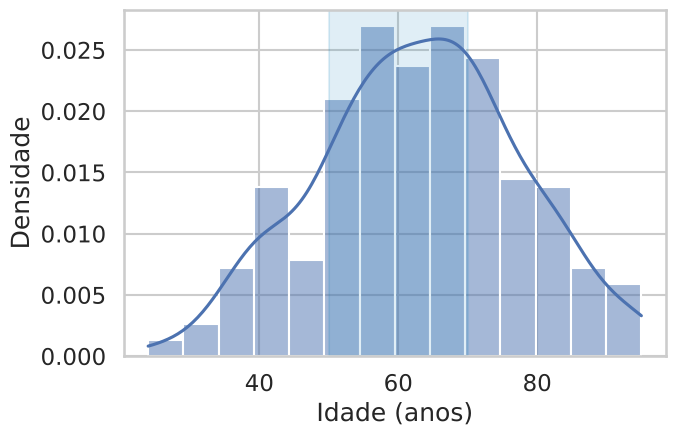

In [ ]:
sns.set_theme(style="whitegrid", context="talk")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(data=df, x="idade", stat="density",
             binwidth=5, kde=True, ax=ax)
ax.axvspan(50, 70, color="#007bba", alpha=0.12)
ax.set(xlabel="Idade (anos)", ylabel="Densidade")

entre = df["idade"].between(50, 70).mean()
print(f"Entre 50 e 70 anos: {entre:.0%}")
plt.show()

### Slide 14 · A curva normal como modelo

média = 63.0 | desvio-padrão = 14.4


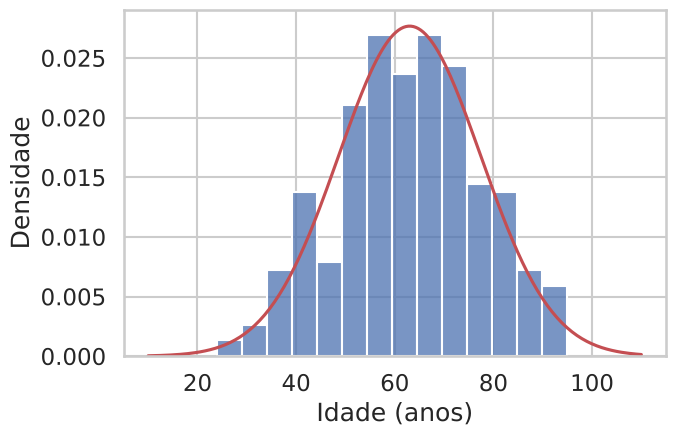

In [ ]:
from scipy import stats

m, s = df["idade"].mean(), df["idade"].std()
x = np.linspace(10, 110, 200)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.histplot(data=df, x="idade", stat="density",
             binwidth=5, ax=ax)
ax.plot(x, stats.norm.pdf(x, m, s), color="#c44e52")
ax.set(xlabel="Idade (anos)", ylabel="Densidade")
print(f"média = {m:.1f} | desvio-padrão = {s:.1f}")
plt.show()

### Slide 15 · Escore z: a distância em desvios-padrão

In [ ]:
m, s = df["idade"].mean(), df["idade"].std()
df["idade_z"] = (df["idade"] - m) / s

print(df["idade_z"].agg(["mean", "std"]).round(2))
df[["idade", "idade_z"]].head(4).round(2)

mean    0.0
std     1.0
Name: idade_z, dtype: float64


,idade,idade_z
0,60.0,-0.21
1,72.0,0.62
2,49.0,-0.97
3,39.0,-1.67


## 03 · Correlação

### Slide 17 · O que o coeficiente resume

A figura do slide; o código não aparece nele. Três nuvens simuladas de 150 pontos.

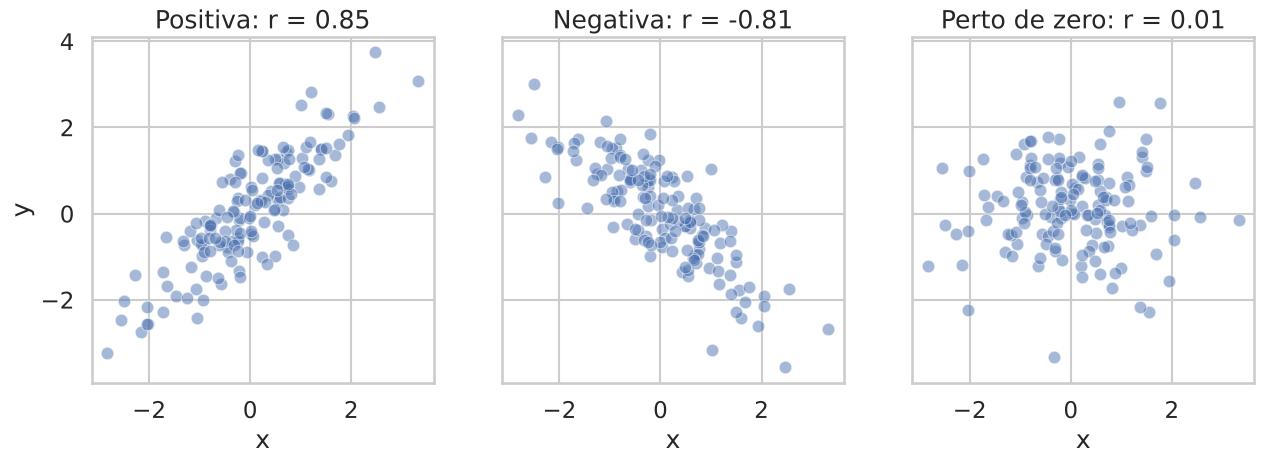

In [ ]:
rng = np.random.default_rng(3)
x = rng.normal(size=150)
casos = {"Positiva": x + rng.normal(scale=0.7, size=150),
         "Negativa": -x + rng.normal(scale=0.7, size=150),
         "Perto de zero": rng.normal(size=150)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (nome, y) in zip(axes, casos.items()):
    sns.scatterplot(x=x, y=y, alpha=0.5, ax=ax)
    r = pd.Series(x).corr(pd.Series(y))
    ax.set(title=f"{nome}: r = {r:.2f}", xlabel="x", ylabel="y")
plt.show()

### Slide 18 · Pearson: idade e tempo de internação

r de Pearson = 0.13


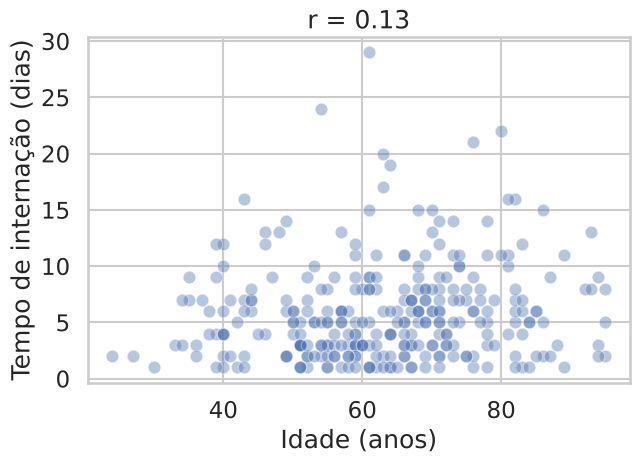

In [ ]:
dias = "tempo_internacao_dias"
pares = df[["idade", dias]].dropna()
r = pares["idade"].corr(pares[dias])   # Pearson
print(f"r de Pearson = {r:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=pares, x="idade", y=dias,
                alpha=0.4, ax=ax)
ax.set(xlabel="Idade (anos)",
       ylabel="Tempo de internação (dias)",
       title=f"r = {r:.2f}")
plt.show()

### Slide 19 · Spearman: a ordem, não a reta

In [ ]:
rho = pares["idade"].corr(pares[dias],
                         method="spearman")
print(f"rho de Spearman = {rho:.2f}")

postos = pares.rank()          # valores -> posições
print(postos.head(3))
r_postos = postos["idade"].corr(postos[dias])
print(f"Pearson dos postos = {r_postos:.2f}")

rho de Spearman = 0.15
   idade  tempo_internacao_dias
0  126.0                  229.0
1  223.0                   89.5
2   47.5                   51.5
Pearson dos postos = 0.15


### Slide 20 · Várias correlações de uma vez

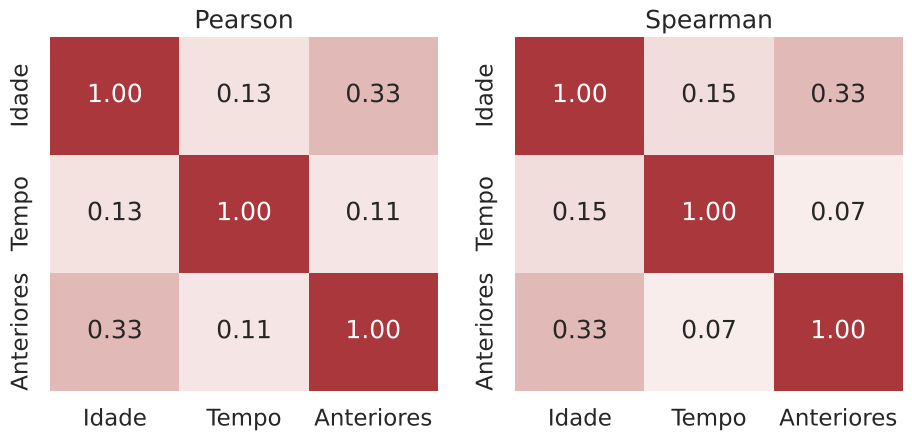

In [ ]:
num = df[["idade", dias, "internacoes_anteriores"]]
num.columns = ["Idade", "Tempo", "Anteriores"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, met in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(num.corr(method=met), annot=True,
                fmt=".2f", vmin=-1, vmax=1, center=0,
                cmap="vlag", cbar=False, ax=ax)
    ax.set_title(met.capitalize())
plt.show()

### Slide 21 · Duas armadilhas que só o gráfico mostra



sem o extremo: Pearson 0.05 | Spearman 0.07
com o extremo: Pearson 0.65 | Spearman 0.20
em U: Pearson 0.00 | Spearman -0.01


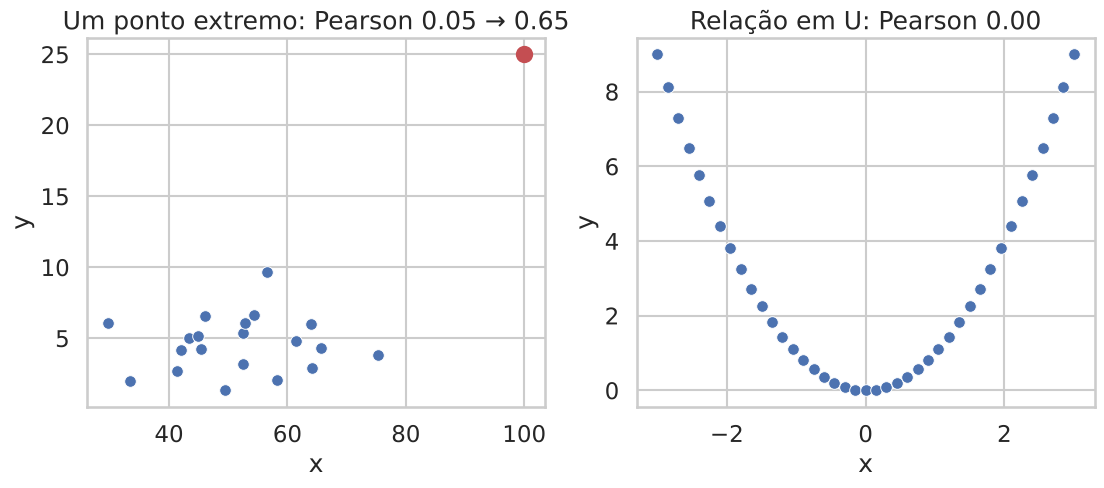

In [ ]:
rng = np.random.default_rng(9)
a = pd.DataFrame({"x": rng.normal(50, 10, 20),
                  "y": rng.normal(5, 2, 20)})
extremo = pd.DataFrame({"x": [100], "y": [25]})
com_extremo = pd.concat([a, extremo])
xu = np.linspace(-3, 3, 41)
u = pd.DataFrame({"x": xu, "y": xu ** 2})

for nome, d in [("sem o extremo", a), ("com o extremo", com_extremo), ("em U", u)]:
    r = round(d["x"].corr(d["y"]), 2) + 0.0
    rho = round(d["x"].corr(d["y"], method="spearman"), 2) + 0.0
    print(f"{nome}: Pearson {r:.2f} | Spearman {rho:.2f}")

r0, r1 = a["x"].corr(a["y"]), com_extremo["x"].corr(com_extremo["y"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=a, x="x", y="y", s=70, ax=axes[0])
axes[0].scatter(extremo["x"], extremo["y"], color="#c44e52", s=120, zorder=3)
axes[0].set_title(f"Um ponto extremo: Pearson {r0:.2f} → {r1:.2f}")
sns.scatterplot(data=u, x="x", y="y", s=70, ax=axes[1])
axes[1].set_title("Relação em U: Pearson 0.00")
plt.show()